# 02 · Medir sin engañarse
**Entornos:** los tres · **Tiempo de ejecución:** ≤ 4 min en CPU · **Criterio de la lección:** tamaño de muestra, Elo, sesgo de asiento y evaluación pareada
medidos con n ≥ 1000 (los cuatro chequeos de la sección 6).

## 1. La idea en una frase
Un resultado de RL es una **variable aleatoria**: sin un intervalo de confianza y sin saber cuántas partidas hicieron falta, "A le gana a B" no significa nada.

**En el sistema de Luca:** la arena local con un $n$ fijo por par de agentes, Elo y semillas pareadas deciden qué modelo se sube.
**En un problema de negocio:** comparar dos reglas de despacho sobre los mismos días simulados, con el IC de la diferencia.

## 2. La intuición y la fórmula
- **IC de una media** (aproximación normal): $\bar x \pm z\, s/\sqrt{n}$, con $z = 1{,}96$ para 95 %.
- **IC de una proporción** (Wilson): centro $\frac{\hat p + z^2/2n}{1+z^2/n}$, semiancho $\frac{z}{1+z^2/n}\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}$.
- **Tamaño de muestra** para semiancho $h$: $n = \lceil z^2\, p(1-p)/h^2 \rceil$ (proporción) o $\lceil (z\sigma/h)^2 \rceil$ (media).
- **Evaluación pareada:** si A y B juegan las mismas semillas, la diferencia por semilla $d_i = a_i - b_i$ tiene mucha menos varianza que $a_i$ y $b_i$ por separado.
- **Elo:** $P(i \text{ gana a } j) = 1/(1+10^{(r_j-r_i)/400})$; los ratings salen de máxima verosimilitud sobre la matriz de victorias.

In [1]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, seed_everything
from rlf.eval.stats import (mean_ci, paired_diff_ci, proportion_ci, sample_size_proportion, sample_size_mean,
                            passes_lower, require_n, InsufficientSample)
from rlf.eval.arena import evaluate_policy, play_games, elo_ratings
from rlf.envs.despacho import DespachoEnv
from rlf.envs.cartas import CartasEnv
from rlf.agents.baselines import RandomPolicy, GreedyDespacho
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
rng = np.random.default_rng(TRAIN_SEED)

## 3. El núcleo: el IC de una media, escrito a mano
Lo escribimos inline y comprobamos que coincide con `rlf.eval.stats.mean_ci` (que usa el resto del curso).

In [2]:
def my_mean_ci(x, z=1.959963984540054):
    x = np.asarray(x, dtype=float)
    se = x.std(ddof=1) / math.sqrt(len(x))          # error estándar de la media
    return x.mean() - z * se, x.mean() + z * se

sample = rng.normal(5.0, 2.0, 1000)
lo, hi = my_mean_ci(sample)
ref = mean_ci(sample)
assert abs(lo - ref.lo) < 1e-12 and abs(hi - ref.hi) < 1e-12
print(f"IC a mano [{lo:.4f}, {hi:.4f}] = IC de rlf [{ref.lo:.4f}, {ref.hi:.4f}]")

# la guardia del curso: no se puede afirmar con menos de 1000 muestras
try:
    passes_lower(mean_ci(sample[:999]), 0.0)
except InsufficientSample as e:
    print("guardia n ≥ 1000:", e)

IC a mano [4.7828, 5.0251] = IC de rlf [4.7828, 5.0251]
guardia n ≥ 1000: n=999 < 1000: not enough samples to make a claim


## 4. Cuánto varía el resultado: una moneda justa
Repetimos "tirar n monedas" 2000 veces y miramos cuánto se dispersa la tasa observada.

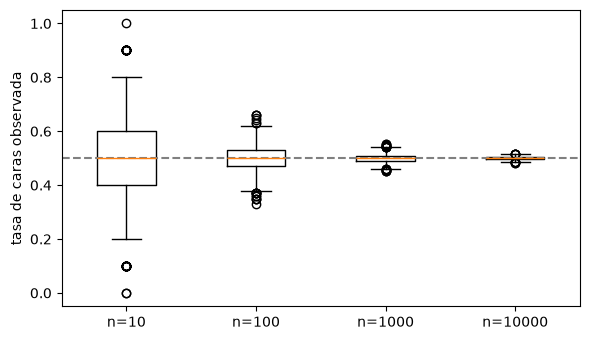

n=   10: desviación estándar de la tasa 0.1601   (teoría 0.1581)
n=  100: desviación estándar de la tasa 0.0488   (teoría 0.0500)
n= 1000: desviación estándar de la tasa 0.0153   (teoría 0.0158)
n=10000: desviación estándar de la tasa 0.0050   (teoría 0.0050)


In [3]:
NS = [10, 100, 1000, 10000]
spread = {n: (rng.binomial(n, 0.5, 2000) / n) for n in NS}
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot([spread[n] for n in NS], tick_labels=[f"n={n}" for n in NS])
ax.axhline(0.5, color="gray", ls="--"); ax.set_ylabel("tasa de caras observada")
plt.tight_layout(); plt.show()
for n in NS:
    print(f"n={n:5d}: desviación estándar de la tasa {spread[n].std():.4f}   (teoría {math.sqrt(0.25 / n):.4f})")

## 5. Experimentos "predice antes de correr"
### Experimento 1 · ¿Cuánto varía la tasa de victoria de una moneda justa con n = 10, 100, 1000, 10000?
**Predice:** la desviación estándar de la tasa observada, ¿cómo escala con $n$? (mira el gráfico y la tabla de arriba).

In [4]:
sds = np.array([spread[n].std() for n in NS])
theory = np.sqrt(0.25 / np.array(NS))
print(np.round(sds, 4), np.round(theory, 4))
assert np.all(np.abs(sds / theory - 1) < 0.1)             # coincide con sqrt(p(1-p)/n) dentro de 10 %
assert sds[0] / sds[2] > 8                                # 100 veces más partidas => 10 veces menos dispersión

[0.1601 0.0488 0.0153 0.005 ] [0.1581 0.05   0.0158 0.005 ]


<details><summary>Respuesta esperada</summary>

La dispersión cae como $1/\sqrt{n}$: ≈ 0,158 con n = 10, ≈ 0,050 con 100, ≈ 0,016 con 1000 y ≈ 0,005 con 10 000. Con 10 partidas,
una moneda justa "gana" entre 20 % y 80 % de las veces sin ninguna habilidad. Para dividir el ruido por 10 hacen falta 100 veces más partidas.
</details>

### Experimento 2 · ¿Cuántas partidas hacen falta para distinguir 55 % de 50 %?
**Predice:** con un agente que de verdad gana 55 %, ¿qué fracción de las veces el IC de Wilson excluye 0,5, con n = 100, 400, 1000, 2000?

In [5]:
def power(n, p_true=0.55, reps=2000):
    wins = rng.binomial(n, p_true, reps)
    return np.mean([proportion_ci(int(w), n).lo > 0.5 for w in wins])

pw = {n: power(n) for n in (100, 400, 1000, 2000)}
print({n: round(v, 3) for n, v in pw.items()})
print("n para semiancho 0,03 con p=0,5:", sample_size_proportion(0.5, 0.03))
assert pw[100] < 0.35 and pw[1000] > 0.8 and pw[2000] > 0.98
assert pw[100] < pw[400] < pw[1000] < pw[2000]

{100: np.float64(0.195), 400: np.float64(0.538), 1000: np.float64(0.884), 2000: np.float64(0.992)}
n para semiancho 0,03 con p=0,5: 1068


<details><summary>Respuesta esperada</summary>

Con n = 100 el IC casi nunca excluye 0,5 (≈ 20 %); con n = 400 ≈ 54 %; con n = 1000 ≈ 88 %; con n = 2000 ≈ 99 %. Para una diferencia de 5 puntos hacen falta
del orden de mil partidas para detectarla de forma fiable. Por eso el curso exige n ≥ 1000: es el mínimo para afirmar diferencias de ese tamaño.
</details>

### Experimento 3 · ¿El asiento 0 de MiniCartas gana más o menos que el 1 con política aleatoria?
**Predice el signo.** El jugador 0 roba primero y, como pierde quien no puede robar (R6), agota su mazo un turno antes. n = 5000 partidas.

In [6]:
match = play_games(lambda: CartasEnv(), RandomPolicy(TRAIN_SEED), RandomPolicy(TRAIN_SEED + 1), 5000)
seat = proportion_ci(match.seat0_wins, match.n)
print(f"P(gana el asiento 0) = {seat.mean:.3f}  IC95 [{seat.lo:.3f}, {seat.hi:.3f}]")
assert seat.hi < 0.5

P(gana el asiento 0) = 0.396  IC95 [0.382, 0.409]


<details><summary>Respuesta esperada</summary>

El asiento 0 **pierde más**: ≈ 0,40 de victorias (IC ≈ [0,38; 0,41]), muy por debajo de 0,5. Es un sesgo del juego, no de los agentes: por eso `play_games`
intercambia los asientos con la misma semilla y en cada comparación de agentes se juegan la mitad de las partidas en cada asiento.
</details>

### Experimento 4 · ¿Comparar por semilla pareada estrecha el IC?
**Predice:** aleatorio vs `GreedyDespacho` en MiniDespacho mediano, mismas 1000 semillas. ¿Cuánto más angosto es el IC pareado que el de dos muestras independientes?

In [7]:
make = lambda: DespachoEnv.from_size("mediano")
rand_ret = evaluate_policy(make, RandomPolicy(TRAIN_SEED), 1000)
greedy_ret = evaluate_policy(make, GreedyDespacho(), 1000)
paired = paired_diff_ci(greedy_ret, rand_ret)
half_paired = (paired.hi - paired.lo) / 2
half_unpaired = 1.959963984540054 * math.sqrt(rand_ret.var(ddof=1) / 1000 + greedy_ret.var(ddof=1) / 1000)
corr = np.corrcoef(rand_ret, greedy_ret)[0, 1]
print(f"greedy − aleatorio = {paired.mean:.1f}   semiancho pareado {half_paired:.2f}  sin parear {half_unpaired:.2f}  "
      f"razón {half_paired / half_unpaired:.2f}  (correlación entre agentes {corr:.2f})")
assert half_paired / half_unpaired <= 0.8

greedy − aleatorio = 40.7   semiancho pareado 3.41  sin parear 6.82  razón 0.50  (correlación entre agentes 0.76)


<details><summary>Respuesta esperada</summary>

El IC pareado mide la mitad (razón ≈ 0,50: semiancho ≈ 3,4 contra ≈ 6,8). Los dos agentes comparten la misma suerte por semilla
(mismos pedidos y ubicaciones; correlación ≈ 0,76), y restar por semilla cancela esa parte. Es como tener ≈ 4 veces más partidas gratis.
</details>

## 6. Criterio de la lección

In [8]:
# (a) chequeo determinista: tamaño de muestra para semiancho 0,03
ok_a = sample_size_proportion(0.5, 0.03) == 1068

# (b) Elo: 3 agentes sintéticos de ratings 1000/1100/1200, n = 1000 partidas por par
true = np.array([1000.0, 1100.0, 1200.0])
W = np.full((3, 3), np.nan)
for i in range(3):
    for j in range(i + 1, 3):
        p_ij = 1 / (1 + 10 ** ((true[j] - true[i]) / 400))
        wins = rng.binomial(1000, p_ij)
        W[i, j], W[j, i] = wins / 1000, 1 - wins / 1000
est_ratings = elo_ratings(W, 1000, anchor=0, anchor_rating=1000.0)
err_b = np.abs(est_ratings - true).max()
ok_b = err_b <= 40

# (c) sesgo de asiento (R7): el IC de P(gana asiento 0) excluye 0,5 con n = 5000
ok_c = (seat.hi < 0.5 or seat.lo > 0.5) and seat.n == 5000

# (d) evaluación pareada: semiancho pareado ≤ 0,8 × el sin parear (n = 1000 semillas)
ratio_d = half_paired / half_unpaired
ok_d = ratio_d <= 0.8 and paired.n == 1000

print(f"{'afirmación':58s} resultado")
print(f"{'(a) sample_size_proportion(0.5, 0.03) = %d (esperado 1068)' % sample_size_proportion(0.5, 0.03):58s} {ok_a}")
print(f"{'(b) Elo recuperado %s, error máx %.1f ≤ 40' % (np.round(est_ratings).astype(int).tolist(), err_b):58s} {ok_b}")
print(f"{'(c) P(asiento 0) = %.3f [%.3f, %.3f] excluye 0,5' % (seat.mean, seat.lo, seat.hi):58s} {ok_c}")
print(f"{'(d) semiancho pareado / sin parear = %.2f ≤ 0,8' % ratio_d:58s} {ok_d}")
assert ok_a and ok_b and ok_c and ok_d

afirmación                                                 resultado
(a) sample_size_proportion(0.5, 0.03) = 1068 (esperado 1068) True
(b) Elo recuperado [1000, 1091, 1188], error máx 12.0 ≤ 40 True
(c) P(asiento 0) = 0.396 [0.382, 0.409] excluye 0,5        True
(d) semiancho pareado / sin parear = 0.50 ≤ 0,8            True


## 7. Resumen y puente a la lección siguiente
- Un número sin IC no es un resultado; con n = 10 una moneda parece "habilidosa". El curso exige n ≥ 1000 y lo hace cumplir en código.
- Comparar sobre las mismas semillas estrecha el IC; en juegos de dos jugadores hay que intercambiar asientos porque el asiento 0 de MiniCartas pierde más.
- **Lección 3:** dejamos de medir a ciegas y resolvemos un problema completo *con el modelo conocido*: MDP, ecuación de Bellman y value iteration.